# 02. 데이터 전처리 및 분할 검증

> README **6.2 데이터 전처리**, **5.2 Target 클래스 분포**에 대응하는 노트북입니다.

**목적**
01 EDA에서 내린 결정을 원본 데이터에 적용해 팀 공통 전처리 데이터(`data/processed/Faults_processed.csv`)를 만들고, 팀 공통 Train/Test 분할이 올바른지 검증합니다.

**전제**
- `src/make_split.py`를 먼저 실행해 `data/split/train_idx.csv`, `test_idx.csv`가 있어야 합니다.
- 여기서 하는 전처리는 **행 단위 변환·열 제거**뿐이며, 데이터로부터 통계를 학습하는 처리(Scaling 등)는 없습니다. 따라서 전체 데이터에 적용해도 Test 정보가 새지 않습니다. 통계를 학습하는 처리는 모델링 단계의 Pipeline 안에서 Train fold 기준으로만 합니다.

| 섹션 | 내용 | 근거 |
|---|---|---|
| 1 | 품질 재확인 (결측·중복·Target 구조) | 01 EDA 3장 |
| 2 | Target 단일화 및 표기 수정 | 01 EDA 3장 (누수 방지) |
| 3 | 강종 변수 정리 | 01 EDA 3·5장 |
| 4 | 저장 및 검증 | |
| 5 | Train/Test 분할 검증 | 층화 분할 확인 |

In [1]:
import sys
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 노트북 위치와 무관하게 프로젝트 루트(src/config.py가 있는 폴더)를 찾는다
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# 한글 폰트: OS별로 있는 폰트를 순서대로 사용
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic",
                               "Noto Sans CJK KR", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.width", 200)

## 1. 품질 재확인

EDA는 Train만 봤으므로, 전처리를 적용할 **전체 데이터** 기준으로 한 번 더 확인합니다.

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "Faults.csv")
print("원본 크기:", df.shape)
print("결측치 합계:", int(df.isna().sum().sum()))
print("중복 행 수 :", int(df.duplicated().sum()))

원본 크기: (1941, 34)
결측치 합계: 0
중복 행 수 : 0


**확인 결과:** 전체 데이터에서도 결측치·중복 행이 0건이므로 별도 처리하지 않습니다.

## 2. Target 단일화 및 표기 수정

- 원본 열 이름 `K_Scatch`를 `K_Scratch`로 수정합니다. 결과표·대시보드 표기를 통일하기 위함입니다.
- 7개 원-핫 열에서 1인 열의 이름을 `target`으로 만들고, 원-핫 열은 제거합니다. 정답 열이 입력에 남으면 데이터 누수가 됩니다.

In [3]:
df = df.rename(columns={"K_Scatch": "K_Scratch"})

TARGETS = ["Pastry", "Z_Scratch", "K_Scratch", "Stains",
           "Dirtiness", "Bumps", "Other_Faults"]

# 원-핫 구조 검증: 정확히 하나만 1이어야 idxmax 결과가 유일하다
assert (df[TARGETS].sum(axis=1) == 1).all(), "원-핫 합이 1이 아닌 행이 있습니다."

df["target"] = df[TARGETS].idxmax(axis=1)
df_processed = df.drop(columns=TARGETS)

print("변환 전:", df.shape, "→ 변환 후:", df_processed.shape)
df_processed["target"].value_counts()

변환 전: (1941, 35) → 변환 후: (1941, 28)


target
Other_Faults    673
Bumps           402
K_Scratch       391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64

## 3. 강종 변수 정리

EDA에서 `TypeOfSteel_A300`과 `TypeOfSteel_A400`이 Train에서 완전히 상호배타적임을 확인했습니다. 전체 데이터에서도 같은지 확인한 뒤 `A400`을 제거합니다. 남은 `TypeOfSteel_A300`은 1 = A300, 0 = A400을 의미합니다.

In [4]:
steel = df_processed[["TypeOfSteel_A300", "TypeOfSteel_A400"]]
print(steel.value_counts().sort_index().to_string())
assert (steel.sum(axis=1) == 1).all(), "두 강종 열이 상호배타적이지 않습니다."

df_processed = df_processed.drop(columns=["TypeOfSteel_A400"])
print("\n최종 크기:", df_processed.shape, "(Feature 26개 + target)")

TypeOfSteel_A300  TypeOfSteel_A400
0                 1                   1164
1                 0                    777

최종 크기: (1941, 27) (Feature 26개 + target)


## 4. 저장 및 검증

In [5]:
out_path = PROJECT_ROOT / "data" / "processed" / "Faults_processed.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
df_processed.to_csv(out_path, index=False)

check = pd.read_csv(out_path)
print("저장 경로:", out_path.relative_to(PROJECT_ROOT))
print("크기     :", check.shape)
print("결측치   :", int(check.isna().sum().sum()))
print("중복 행  :", int(check.duplicated().sum()))
print("원-핫/강종 열 잔존:", [c for c in TARGETS + ["TypeOfSteel_A400"] if c in check.columns])

저장 경로: data/processed/Faults_processed.csv
크기     : (1941, 27)
결측치   : 0
중복 행  : 0
원-핫/강종 열 잔존: []


## 5. Train/Test 분할 검증

`make_split.py`는 `config.py`의 설정(80:20, `random_state=42`, Target 기준 층화)으로 인덱스를 만듭니다. 여기서는 ① 분할 자체에 문제가 없는지, ② 유형별 비율이 유지되는지, ③ Test에서 결과가 불안정할 유형이 있는지 확인합니다.

In [6]:
tr = pd.read_csv(PROJECT_ROOT / "data" / "split" / "train_idx.csv")["index"]
te = pd.read_csv(PROJECT_ROOT / "data" / "split" / "test_idx.csv")["index"]
y_all = df_processed["target"]

checks = {
    "Train·Test 겹치는 행": len(set(tr) & set(te)),
    "누락된 행": len(df_processed) - len(set(tr) | set(te)),
    "Train 내 중복 인덱스": len(tr) - tr.nunique(),
    "Test 내 중복 인덱스": len(te) - te.nunique(),
}
for k, v in checks.items():
    print(f"{'OK' if v == 0 else 'NG'}  {k}: {v}")
print(f"\nTrain {len(tr)}건 / Test {len(te)}건 (Test 비율 {len(te) / len(df_processed):.4f})")

OK  Train·Test 겹치는 행: 0
OK  누락된 행: 0
OK  Train 내 중복 인덱스: 0
OK  Test 내 중복 인덱스: 0

Train 1552건 / Test 389건 (Test 비율 0.2004)


In [7]:
ratio = pd.DataFrame({
    "Train 건수": y_all.loc[tr].value_counts(),
    "Test 건수": y_all.loc[te].value_counts(),
    "전체 비율": y_all.value_counts(normalize=True),
    "Train 비율": y_all.loc[tr].value_counts(normalize=True),
    "Test 비율": y_all.loc[te].value_counts(normalize=True),
})
ratio["전체와 최대 차이"] = ratio[["Train 비율", "Test 비율"]].sub(ratio["전체 비율"], axis=0).abs().max(axis=1)
display(ratio)
print(f"최대 비율 차이: {ratio['전체와 최대 차이'].max():.4f}")

print("\n[Test 20건 미만 유형 → 1건 차이로 Recall이 크게 움직임]")
for name, n in ratio["Test 건수"][ratio["Test 건수"] < 20].items():
    print(f"  {name:10s} Test {n}건 → 1건당 Recall {1 / n:.3f}")

,Train 건수,Test 건수,전체 비율,Train 비율,Test 비율,전체와 최대 차이
target,,,,,,
Other_Faults,538,135,0.3467,0.3466,0.3470,0.0003
Bumps,321,81,0.2071,0.2068,0.2082,0.0011
K_Scratch,313,78,0.2014,0.2017,0.2005,0.0009
Z_Scratch,152,38,0.0979,0.0979,0.0977,0.0002
Pastry,126,32,0.0814,0.0812,0.0823,0.0009
Stains,58,14,0.0371,0.0374,0.0360,0.0011
Dirtiness,44,11,0.0283,0.0284,0.0283,0.0001


최대 비율 차이: 0.0011

[Test 20건 미만 유형 → 1건 차이로 Recall이 크게 움직임]
  Stains     Test 14건 → 1건당 Recall 0.071
  Dirtiness  Test 11건 → 1건당 Recall 0.091


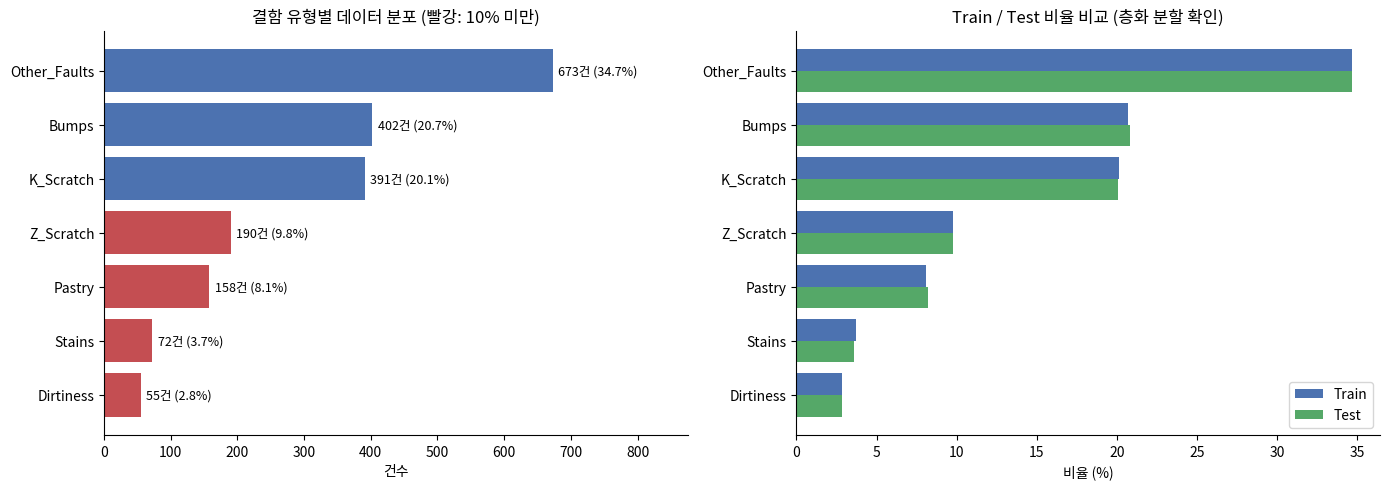

In [8]:
order = y_all.value_counts().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cnt = y_all.value_counts()[order]
pct = cnt / cnt.sum() * 100
b = axes[0].barh(cnt.index, cnt.values,
                 color=["#C44E52" if p < 10 else "#4C72B0" for p in pct])
axes[0].bar_label(b, labels=[f"{n}건 ({p:.1f}%)" for n, p in zip(cnt, pct)], padding=4, fontsize=9)
axes[0].set_xlim(0, cnt.max() * 1.3)
axes[0].set_xlabel("건수")
axes[0].set_title("결함 유형별 데이터 분포 (빨강: 10% 미만)")

pos = np.arange(len(order))
axes[1].barh(pos + 0.2, ratio.loc[order, "Train 비율"] * 100, height=0.4, color="#4C72B0", label="Train")
axes[1].barh(pos - 0.2, ratio.loc[order, "Test 비율"] * 100, height=0.4, color="#55A868", label="Test")
axes[1].set_yticks(pos, order)
axes[1].set_xlabel("비율 (%)")
axes[1].set_title("Train / Test 비율 비교 (층화 분할 확인)")
axes[1].legend(loc="lower right")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**확인 결과**
- 분할 무결성 검사는 모두 0건으로 정상입니다.
- 유형별 비율 차이는 최대 0.0011로, 층화 분할이 정상적으로 이루어졌습니다.
- Test의 Stains(14건)·Dirtiness(11건)는 1건 차이로 Recall이 각각 0.071, 0.091씩 움직입니다. → **최종 Test 결과에서 이 두 유형의 수치는 변동 폭을 감안해 해석합니다.**

## 전처리 결정 기록

| 결정 | 근거 | 결과 |
|---|---|---|
| 원-핫 7개 열 → `target` | 모든 행의 원-핫 합 = 1, 정답 열 잔존 시 누수 | 단일 다중 분류 Target |
| `K_Scatch` → `K_Scratch` | 표기 통일 | |
| `TypeOfSteel_A400` 제거 | A300과 완전 상호배타 | 정보 손실 없음, Feature 26개 |
| 결측·중복·극단값 처리 없음 | 0건 / 오류 근거 없음 | |
| 층화 80:20 분할 (`random_state=42`) | 유형 비율 유지 | 비율 차이 최대 0.0011 |